In [1]:
%load_ext autoreload
%autoreload 2

import requests, json, time
import os
import numpy as np
import matplotlib.pyplot as plt
import random as rnd
from tqdm.notebook import tqdm
import re
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree as et
from collections import Counter
import birth_death_utils as bd
import artificial_collations as ac
import pickle

tei_ns = "http://www.tei-c.org/ns/1.0"
xml_ns = "http://www.w3.org/XML/1998/namespace"

# Chrestien, _Cligès_ (~2500 v., variantes typées)

## Load TEI file and count distributions

In [2]:
with open('texts/cliges_unified_fixed_unique.xml', 'r') as f:
    parser = et.XMLParser(remove_comments=True)
    file = et.parse(f, parser=parser)

lines = file.xpath('/TEI/text[1]/body[1]')[0].getchildren()
loci = file.findall(".//app")
type_list = []
for app in loci:
    if "type" in app.attrib:
        type_list.append(app.attrib[f'type'])

for k,v in Counter(type_list).items():
    print(f'{k} : {v}')

graphemic : 2634
lexsem:weak : 644
absence : 653
lexsem:strong : 739
morphologic : 284
morphosyntactic : 811
order : 231
lexsem:nonsense : 143
lexsem : 2
lex:nonsense : 1
lexsem:wit : 5
nonsense : 1
lexsem:subtype : 5
lexsem:structure : 1
ansanble : 1
lexsem:graphemic : 1


In [3]:
type_families = {
    'sequential' :('order','absence'),
    'semantic' : ('lexsem:strong','lexsem:nonsense'),
    'grammatical' : ('morphologic','morphosyntactic'),
    'graphic' : ('graphemic','lexsem:graphemic','lexsem:weak')}

app_nb_per_line = {k:[] for k in type_families}
rdg_nb_per_app = {k:[] for k in type_families}

non_typed = []

for l in lines:
    var_list = l.findall('.//app')

    for k in type_families.keys():
        app_nb_per_line[k].append(0)

    for app in var_list:
        if not 'type' in app.attrib:
            if not f'{{{xml_ns}}}id' in app.attrib:
                print('<app> element without @id at', l.attrib[f'{{{xml_ns}}}id'])
            else:
                non_typed.append(app.attrib[f'{{{xml_ns}}}id'])
        else:
            for varname, vartypes in type_families.items():
                if app.attrib['type'] in vartypes:
                    app_nb_per_line[varname][-1] += 1
                    rdg_nb_per_app[varname].append(len(app.getchildren()))

print(f'There are {len(non_typed)} <app> without @type in file')

<app> element without @id at l-636bis
There are 460 <app> without @type in file


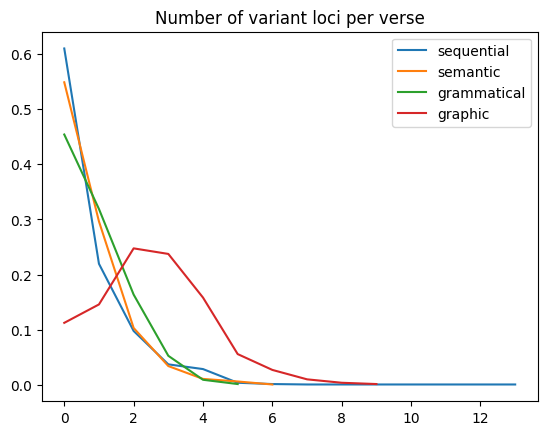

In [4]:
ax = plt.subplot()
for t,v in app_nb_per_line.items():
    c  = Counter(v)
    x,y = list(c.keys()),list(c.values())
    x,y = zip(*sorted(zip(x,y)))
    ax.plot(x,np.array(y)/sum(y),label=t)

ax.legend();
ax.set_title('Number of variant loci per verse');

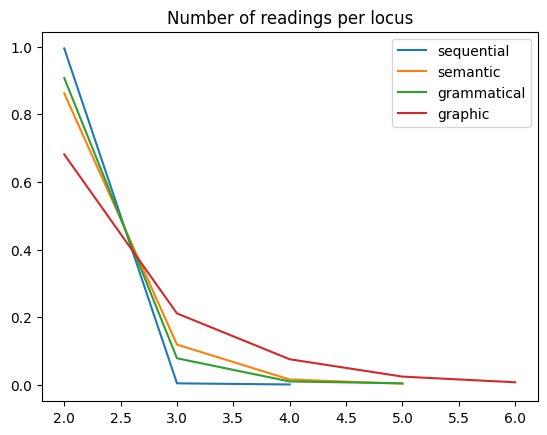

In [5]:
ax = plt.subplot()
for t,v in rdg_nb_per_app.items():
    c  = Counter(v)
    c = {k:v for k,v in c.items() if k!=1}
    x,y = list(c.keys()),list(c.values())
    x,y = zip(*sorted(zip(x,y)))
    ax.plot(x,np.array(y)/sum(y),label=t)

ax.legend();
ax.set_title('Number of readings per locus');

# Simulated traditions

## Some examples

In [4]:
## loading pre-simulated trees with 8 witnesses
with open('simulations_data/trees_8_wits.pickle', 'rb') as f:
    trees_8_wits = pickle.load(f)

# trees_8_wits = [bd.generate_tree_fixed_size(7.*10**(-3), 3.*10**(-3), 1000,1000, 8) for k in range(100)]

In [15]:
p_values = np.linspace(0.01, 0.04, 5)

sim_l, sim_app = [], []
for p_new_locus in tqdm(p_values):
    plot_data_l, plot_data_app = ac.get_variants_distributions(p_new_locus, 0.05, 0.2, 100, trees_8_wits[:30], 50)
    sim_l.append(plot_data_l)
    sim_app.append(plot_data_app)


  0%|          | 0/5 [00:00<?, ?it/s]

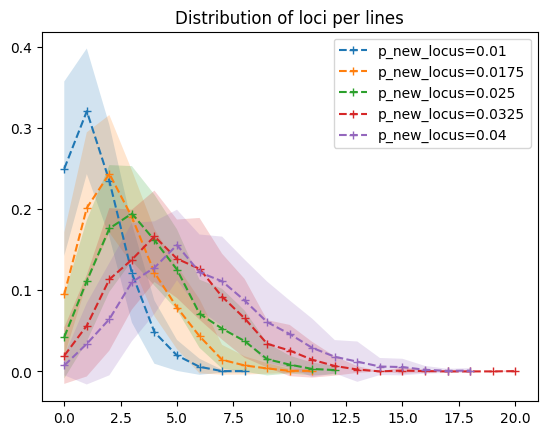

In [16]:
ax = plt.subplot()
for p_new_locus, plot_data in zip(p_values, sim_l):
    X, Y_mean, Y_var = plot_data
    ax.plot(X,Y_mean,'+--',label=f'p_new_locus={p_new_locus}')
    ax.fill_between(X, Y_mean-Y_var,Y_mean+Y_var, alpha=.2)

ax.set_title('Distribution of loci per lines')
ax.legend();

In [18]:
p_values = np.linspace(0.01, 0.1, 5)

sim_l, sim_app = [], []
for p_mod in tqdm(p_values):
    plot_data_l, plot_data_app = ac.get_variants_distributions(0.02, p_mod, 0.2, 100, trees_8_wits[:30], 50)
    sim_l.append(plot_data_l)
    sim_app.append(plot_data_app)


  0%|          | 0/5 [00:00<?, ?it/s]

Text(0.5, 1.0, 'Number  of readings per locus')

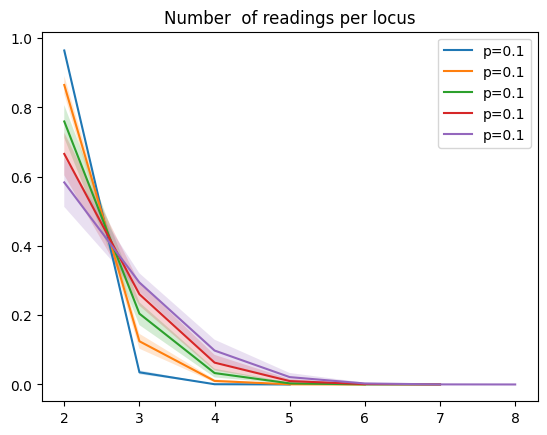

In [19]:
ax = plt.subplot()
for p_new_locus, plot_data in zip(p_values, sim_app):
    X, Y_mean, Y_var = plot_data
    ax.plot(X,Y_mean,label=f'p={p_mod}')
    ax.fill_between(X, Y_mean-Y_var,Y_mean+Y_var, alpha=.2)

ax.legend();
ax.set_title('Number  of readings per locus')